# TrustLens — Python Exploratory Data Analysis

**Project:** A Governed AI Analytics Assistant for E-commerce Delivery and Customer Satisfaction

This notebook performs the Python-based exploratory and business analysis for the Olist e-commerce dataset. It complements the existing PostgreSQL business queries and Power BI dashboard; it does not replace them.

**Local project requirement:** Run this notebook from the TrustLens project in VS Code. The source CSV files are expected in `data/raw/`. Outputs created for reporting are saved in `data/processed/`.

**Business focus**
- Order status and data completeness
- Delivery duration and late-delivery performance
- Customer review scores for late vs. on-time deliveries
- Product-category and seller delivery performance
- Payment methods and monthly sales trends
- A concise business summary and Power BI-ready extracts


## 1. Setup and local file paths

Run this section first. It uses local project folders and does not require Google Colab.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the TrustLens project root.
# This works when the notebook is opened from the project root or its notebook folder.
cwd = Path.cwd()
if (cwd / "data" / "raw").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/raw. Open this notebook from the TrustLens project."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DIR)
print("Processed output folder:", PROCESSED_DIR)


Project root: c:\Users\Asus\Desktop\TrustLens
Raw data folder: c:\Users\Asus\Desktop\TrustLens\data\raw
Processed output folder: c:\Users\Asus\Desktop\TrustLens\data\processed


In [2]:
# Expected source files in data/raw
expected_files = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
    "olist_geolocation_dataset.csv",
]

file_status = pd.DataFrame({
    "file": expected_files,
    "exists": [(RAW_DIR / name).is_file() for name in expected_files]
})
display(file_status)

missing_files = file_status.loc[~file_status["exists"], "file"].tolist()
if missing_files:
    raise FileNotFoundError(f"Missing CSV files in data/raw: {missing_files}")


,file,exists
0,olist_orders_dataset.csv,True
1,olist_order_items_dataset.csv,True
2,olist_order_payments_dataset.csv,True
3,olist_order_reviews_dataset.csv,True
4,olist_customers_dataset.csv,True
5,olist_sellers_dataset.csv,True
6,olist_products_dataset.csv,True
7,product_category_name_translation.csv,True
8,olist_geolocation_dataset.csv,True


## 2. Load the datasets

Load the tables required for the analyses in this notebook. Geolocation is not loaded into memory because it is a large lookup dataset and is not needed for the analyses below.

In [3]:
orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(RAW_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv")
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")
sellers = pd.read_csv(RAW_DIR / "olist_sellers_dataset.csv")
products = pd.read_csv(RAW_DIR / "olist_products_dataset.csv")
category_translation = pd.read_csv(
    RAW_DIR / "product_category_name_translation.csv"
)

datasets = {
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "customers": customers,
    "sellers": sellers,
    "products": products,
    "category_translation": category_translation,
}

dataset_overview = pd.DataFrame([
    {"table": name, "rows": len(df), "columns": len(df.columns)}
    for name, df in datasets.items()
])
display(dataset_overview)


,table,rows,columns
0,orders,99441,8
1,order_items,112650,7
2,payments,103886,5
3,reviews,99224,7
4,customers,99441,5
5,sellers,3095,4
6,products,32951,9
7,category_translation,71,2


In [4]:
# Preview the main orders table
display(orders.head())
orders.info()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


## 3. Data quality and order status

In [5]:
# Missing values in the orders table
orders_missing = (
    orders.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: (x["missing_count"] / len(orders) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
display(orders_missing)


,missing_count,missing_pct
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00


In [6]:
# Order-status distribution
status_summary = (
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("order_status")
    .reset_index(name="order_count")
)
status_summary["percentage"] = (
    status_summary["order_count"] / len(orders) * 100
).round(2)

display(status_summary)


,order_status,order_count,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [7]:
# Check missing delivery timestamps by order status
delivery_missing_by_status = (
    orders.groupby("order_status", dropna=False)
    .agg(
        total_orders=("order_id", "count"),
        missing_customer_delivery_date=(
            "order_delivered_customer_date",
            lambda values: values.isna().sum()
        ),
        missing_carrier_date=(
            "order_delivered_carrier_date",
            lambda values: values.isna().sum()
        )
    )
    .reset_index()
)
display(delivery_missing_by_status)


,order_status,total_orders,missing_customer_delivery_date,missing_carrier_date
0,approved,2,2,2
1,canceled,625,619,550
2,created,5,5,5
3,delivered,96478,8,2
4,invoiced,314,314,314
5,processing,301,301,301
6,shipped,1107,1107,0
7,unavailable,609,609,609


## 4. Delivery performance

Late delivery is defined consistently with the TrustLens business definition: an order is late when its actual customer delivery timestamp is later than its estimated delivery timestamp. The rate below uses delivered orders with both dates available.

In [8]:
# Convert order timestamps to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Keep delivered orders with valid actual and estimated delivery dates
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
].copy()

valid_dates = delivered_orders.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
).copy()

valid_dates["delivery_days"] = (
    valid_dates["order_delivered_customer_date"]
    - valid_dates["order_purchase_timestamp"]
).dt.total_seconds() / 86400

valid_dates["late_delivery"] = (
    valid_dates["order_delivered_customer_date"]
    > valid_dates["order_estimated_delivery_date"]
)

print("All orders:", len(orders))
print("Delivered orders:", len(delivered_orders))
print("Delivered orders with valid dates:", len(valid_dates))
print("Delivered orders excluded due to missing required dates:", len(delivered_orders) - len(valid_dates))


All orders: 99441
Delivered orders: 96478
Delivered orders with valid dates: 96470
Delivered orders excluded due to missing required dates: 8


In [9]:
# Delivery duration summary
delivery_duration_summary = valid_dates["delivery_days"].describe().round(2)
display(delivery_duration_summary.to_frame(name="delivery_days"))

print("Average delivery time:", round(valid_dates["delivery_days"].mean(), 2), "days")
print("Median delivery time:", round(valid_dates["delivery_days"].median(), 2), "days")
print("Fastest delivery:", round(valid_dates["delivery_days"].min(), 2), "days")
print("Slowest delivery:", round(valid_dates["delivery_days"].max(), 2), "days")


,delivery_days
count,96470.00
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
max,209.63


Average delivery time: 12.56 days
Median delivery time: 10.22 days
Fastest delivery: 0.53 days
Slowest delivery: 209.63 days


In [10]:
# Overall late-delivery KPI
late_orders = int(valid_dates["late_delivery"].sum())
orders_with_valid_delivery_dates = len(valid_dates)
late_delivery_rate = (
    late_orders / orders_with_valid_delivery_dates * 100
    if orders_with_valid_delivery_dates else 0
)

delivery_kpis = pd.DataFrame({
    "metric": [
        "Delivered orders",
        "Delivered orders with valid dates",
        "Late orders",
        "Late delivery rate (%)",
        "Average delivery days",
        "Median delivery days",
    ],
    "value": [
        len(delivered_orders),
        orders_with_valid_delivery_dates,
        late_orders,
        round(late_delivery_rate, 2),
        round(valid_dates["delivery_days"].mean(), 2),
        round(valid_dates["delivery_days"].median(), 2),
    ],
})
display(delivery_kpis)


,metric,value
0,Delivered orders,96478.00
1,Delivered orders with valid dates,96470.00
2,Late orders,7826.00
3,Late delivery rate (%),8.11
4,Average delivery days,12.56
5,Median delivery days,10.22


In [11]:
# Orders taking more than 30 days to deliver
long_deliveries = valid_dates.loc[
    valid_dates["delivery_days"] > 30,
    [
        "order_id",
        "delivery_days",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "late_delivery",
    ],
].sort_values("delivery_days", ascending=False)

print("Orders taking more than 30 days:", len(long_deliveries))
display(long_deliveries.head(10))


Orders taking more than 30 days: 4550


,order_id,delivery_days,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,late_delivery
19590,ca07593549f1816d26a572e06dc1eab6,209.628611,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,True
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.351759,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,True
61610,440d0d17af552815d15a9e41abe49359,195.634016,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,True
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.850174,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,True
89130,285ab9426d6982034523a855f55a885e,194.633611,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,True
38509,0f4519c5f1c541ddec9f21b3bddd533a,194.049583,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,True
11399,47b40429ed8cce3aee9199792275433f,191.463542,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,True
81401,2fe324febf907e3ea3f2aa9650869fa5,189.863160,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,True
54480,2d7561026d542c8dbd8f0daeadf67a43,188.134618,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,True
68769,c27815f7e3dd0b926b58552628481575,187.743843,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,True


In [12]:
# Monthly late-delivery performance, grouped by purchase month
valid_dates["purchase_month"] = (
    valid_dates["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_delivery = (
    valid_dates.groupby("purchase_month")
    .agg(
        delivered_orders=("order_id", "nunique"),
        late_orders=("late_delivery", "sum"),
    )
    .reset_index()
)

monthly_delivery["late_delivery_pct"] = (
    monthly_delivery["late_orders"] / monthly_delivery["delivered_orders"] * 100
).round(2)

display(monthly_delivery.tail(12))


,purchase_month,delivered_orders,late_orders,late_delivery_pct
11,2017-09,4150,216,5.20
12,2017-10,4478,237,5.29
13,2017-11,7288,1043,14.31
14,2017-12,5513,462,8.38
15,2018-01,7069,464,6.56
16,2018-02,6555,1048,15.99
17,2018-03,7003,1496,21.36
18,2018-04,6798,361,5.31
19,2018-05,6749,556,8.24
20,2018-06,6096,83,1.36


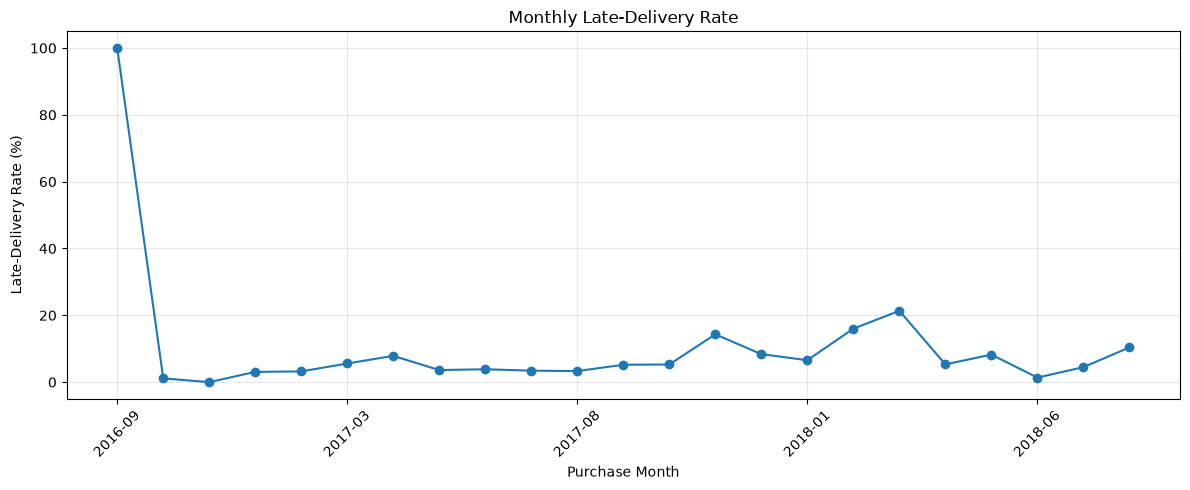

In [13]:
# Monthly late-delivery trend
ax = monthly_delivery.plot(
    x="purchase_month",
    y="late_delivery_pct",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False,
)
ax.set_title("Monthly Late-Delivery Rate")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Customer satisfaction

Reviews are first aggregated to one average score per order. This avoids multiplying order rows when an order has more than one review record.

In [14]:
# Convert review scores to numeric and calculate one score per order
reviews["review_score"] = pd.to_numeric(
    reviews["review_score"], errors="coerce"
)

reviews_per_order = (
    reviews.dropna(subset=["review_score"])
    .groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

print("Review records:", len(reviews))
print("Orders with a numeric review:", reviews_per_order["order_id"].nunique())
print("Overall average review score:", round(reviews["review_score"].mean(), 2))


Review records: 99224
Orders with a numeric review: 98673
Overall average review score: 4.09


In [15]:
# Join one review score per order to valid delivery records
delivery_reviews = valid_dates.merge(
    reviews_per_order,
    on="order_id",
    how="inner",
    validate="one_to_one",
)

review_comparison = (
    delivery_reviews.groupby("late_delivery")
    .agg(
        orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean"),
    )
    .reset_index()
)

review_comparison["delivery_status"] = review_comparison["late_delivery"].map({
    False: "On time / early",
    True: "Late",
})
review_comparison["average_review_score"] = (
    review_comparison["average_review_score"].round(2)
)
display(review_comparison[[
    "delivery_status", "orders", "average_review_score"
]])


,delivery_status,orders,average_review_score
0,On time / early,88163,4.29
1,Late,7661,2.57


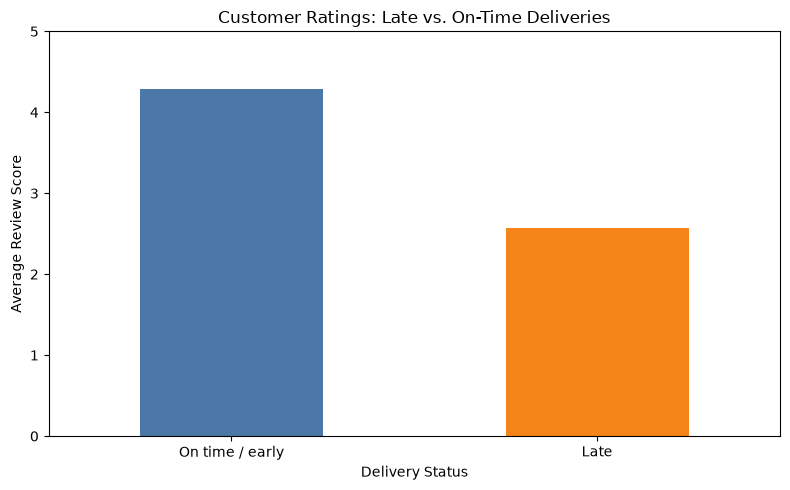

In [16]:
# Compare average review scores visually
plot_reviews = review_comparison.set_index("delivery_status")[
    "average_review_score"
]
ax = plot_reviews.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
    ylim=(0, 5),
    rot=0,
)
ax.set_title("Customer Ratings: Late vs. On-Time Deliveries")
ax.set_xlabel("Delivery Status")
ax.set_ylabel("Average Review Score")
plt.tight_layout()
plt.show()


**Interpretation note:** This is an association between delivery status and review score. It does not, by itself, prove that late delivery caused a lower review score.

## 6. Product-category delivery performance

In [17]:
# Join delivered-order status to order items and product categories
category_delivery = (
    valid_dates[["order_id", "late_delivery"]]
    .merge(
        order_items[["order_id", "product_id"]],
        on="order_id",
        how="inner",
    )
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left",
    )
)

category_delivery["category_english"] = (
    category_delivery["product_category_name_english"]
    .fillna(category_delivery["product_category_name"])
    .fillna("Unknown")
)

print("Order-item rows with delivery status:", len(category_delivery))
display(category_delivery.head())


Order-item rows with delivery status: 110189


,order_id,late_delivery,product_id,product_category_name,product_category_name_english,category_english
0,e481f51cbdc54678b7cc49136f2d6af7,False,87285b34884572647811a353c7ac498a,utilidades_domesticas,housewares,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,False,595fac2a385ac33a80bd5114aec74eb8,perfumaria,perfumery,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,False,aa4383b373c6aca5d8797843e5594415,automotivo,auto,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,False,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,pet_shop,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,False,65266b2da20d04dbe00c5c2d3bb7859e,papelaria,stationery,stationery


In [18]:
# One order is counted once per category
order_category = category_delivery.drop_duplicates(
    subset=["order_id", "category_english"]
)

category_summary = (
    order_category.groupby("category_english")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("late_delivery", "sum"),
    )
    .reset_index()
)

category_summary["late_delivery_pct"] = (
    category_summary["late_orders"] / category_summary["total_orders"] * 100
).round(2)

# Exclude categories with fewer than 100 orders for a more stable comparison
reliable_categories = (
    category_summary.loc[category_summary["total_orders"] >= 100]
    .sort_values("late_delivery_pct", ascending=False)
    .copy()
)

display(reliable_categories.head(10))


,category_english,total_orders,late_orders,late_delivery_pct
5,audio,348,45,12.93
34,fashion_underwear_beach,117,15,12.82
11,books_technical,256,28,10.94
48,home_confort,392,41,10.46
37,food,441,44,9.98
27,electronics,2517,247,9.81
13,christmas_supplies,125,12,9.60
7,baby,2809,258,9.18
58,office_furniture,1254,115,9.17
0,Unknown,1392,127,9.12


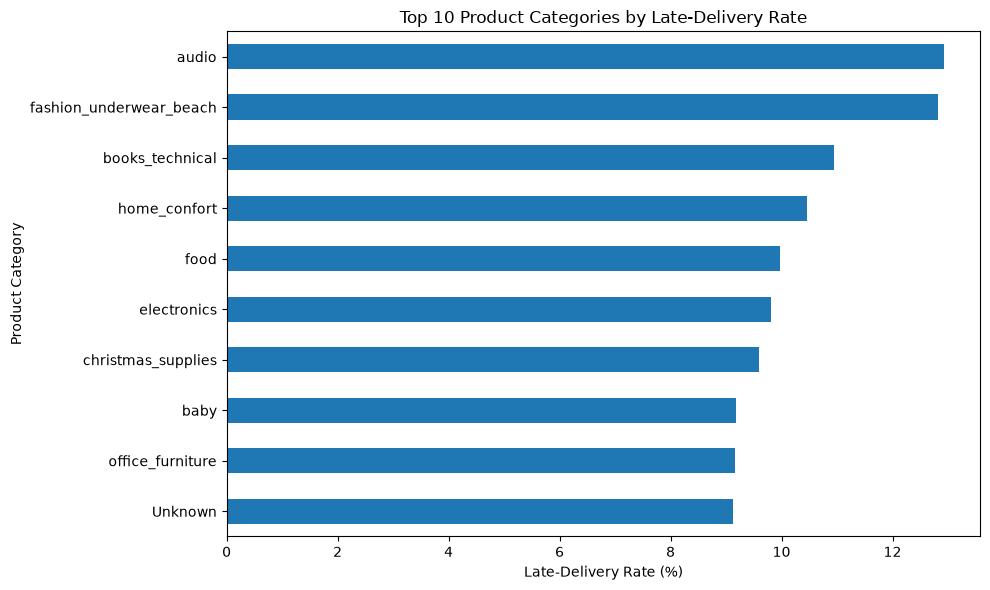

In [19]:
# Top 10 categories by late-delivery rate (minimum 100 orders)
top_categories = reliable_categories.head(10).sort_values("late_delivery_pct")

ax = top_categories.plot(
    x="category_english",
    y="late_delivery_pct",
    kind="barh",
    figsize=(10, 6),
    legend=False,
)
ax.set_title("Top 10 Product Categories by Late-Delivery Rate")
ax.set_xlabel("Late-Delivery Rate (%)")
ax.set_ylabel("Product Category")
plt.tight_layout()
plt.show()


## 7. Seller delivery performance

In [20]:
# Join order items to delivered-order status and seller details
seller_delivery = (
    valid_dates[["order_id", "late_delivery"]]
    .merge(
        order_items[["order_id", "seller_id"]],
        on="order_id",
        how="inner",
    )
    .drop_duplicates(subset=["order_id", "seller_id"])
    .merge(
        sellers[["seller_id", "seller_city", "seller_state"]],
        on="seller_id",
        how="left",
    )
)

seller_summary = (
    seller_delivery.groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("late_delivery", "sum"),
    )
    .reset_index()
)

seller_summary["late_delivery_pct"] = (
    seller_summary["late_orders"] / seller_summary["total_orders"] * 100
).round(2)

# Keep sellers with at least 20 distinct orders
reliable_sellers = (
    seller_summary.loc[seller_summary["total_orders"] >= 20]
    .sort_values("late_delivery_pct", ascending=False)
    .copy()
)

display(reliable_sellers.head(10))


,seller_id,total_orders,late_orders,late_delivery_pct
1543,821fb029fc6e495ca4f08a35d51e53a5,24,9,37.50
2873,f76a3b1349b6df1ee875d1f3fa4340f0,24,9,37.50
2766,ede0c03645598cdfc63ca8237acbe73d,43,15,34.88
2011,ad781527c93d00d89a11eecd9dcad7c1,38,12,31.58
1556,835f0f7810c76831d6c7d24c7a646d4d,42,13,30.95
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,30.14
57,054694fa03fe82cec4b7551487331d74,20,6,30.00
1509,7f152321c60a266edc53af1925ef96c1,20,6,30.00
914,4e5725ba188db8252977a4f0227bd462,21,6,28.57
478,2a1348e9addc1af5aaa619b1a3679d6b,48,13,27.08


## 8. Payment-method analysis

In [21]:
# Ensure payment values are numeric before calculating sums and averages
payments["payment_value"] = pd.to_numeric(
    payments["payment_value"], errors="coerce"
)
payments["payment_installments"] = pd.to_numeric(
    payments["payment_installments"], errors="coerce"
)

payment_summary = (
    payments.groupby("payment_type", dropna=False)
    .agg(
        payment_records=("order_id", "count"),
        total_payment_value=("payment_value", "sum"),
        average_payment=("payment_value", "mean"),
    )
    .sort_values("total_payment_value", ascending=False)
    .round(2)
    .reset_index()
)

display(payment_summary)


,payment_type,payment_records,total_payment_value,average_payment
0,credit_card,76795,12542084.19,163.32
1,boleto,19784,2869361.27,145.03
2,voucher,5775,379436.87,65.70
3,debit_card,1529,217989.79,142.57
4,not_defined,3,0.00,0.00


## 9. Monthly sales and business summary

GMV in this notebook is calculated as the sum of item `price` values. Freight is not included in this GMV measure. The Olist source dataset is Brazilian; monetary values are presented in the source currency (BRL).

In [22]:
# Convert item prices to numeric
order_items["price"] = pd.to_numeric(order_items["price"], errors="coerce")
order_items["freight_value"] = pd.to_numeric(
    order_items["freight_value"], errors="coerce"
)

# Attach purchase timestamp to each order item
sales_data = orders[
    ["order_id", "order_status", "order_purchase_timestamp"]
].merge(
    order_items[["order_id", "product_id", "price", "freight_value"]],
    on="order_id",
    how="inner",
)

sales_data["purchase_month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_sales = (
    sales_data.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        gmv=("price", "sum"),
        freight_value=("freight_value", "sum"),
    )
    .reset_index()
)

monthly_sales["aov"] = (
    monthly_sales["gmv"] / monthly_sales["total_orders"]
).round(2)
monthly_sales["gmv"] = monthly_sales["gmv"].round(2)
monthly_sales["freight_value"] = monthly_sales["freight_value"].round(2)
monthly_sales["gmv_change_pct"] = (
    monthly_sales["gmv"].pct_change() * 100
).round(2)

display(monthly_sales.tail(12))


,purchase_month,total_orders,gmv,freight_value,aov,gmv_change_pct
12,2017-10,4568,664219.43,105092.94,145.41,6.38
13,2017-11,7451,1010271.37,168872.40,135.59,52.10
14,2017-12,5624,743914.17,119633.06,132.27,-26.36
15,2018-01,7220,950030.36,157271.53,131.58,27.71
16,2018-02,6694,844178.71,142730.25,126.11,-11.14
17,2018-03,7188,983213.44,171913.38,136.79,16.47
18,2018-04,6934,996647.75,163050.29,143.73,1.37
19,2018-05,6853,996517.68,153264.14,145.41,-0.01
20,2018-06,6160,865124.31,157552.80,140.44,-13.19
21,2018-07,6273,895507.22,163220.81,142.76,3.51


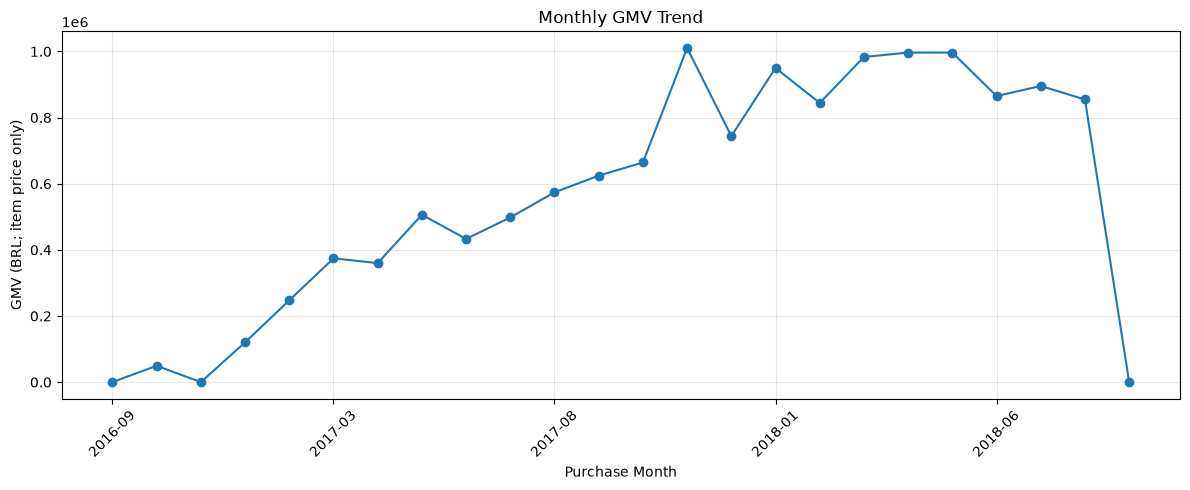

In [23]:
# Monthly GMV trend
ax = monthly_sales.plot(
    x="purchase_month",
    y="gmv",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False,
)
ax.set_title("Monthly GMV Trend")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("GMV (BRL; item price only)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
# Combined business KPI summary
business_summary = pd.DataFrame({
    "metric": [
        "Total orders",
        "Total GMV (BRL; item price only)",
        "Average order value (BRL)",
        "Delivered orders with valid delivery dates",
        "Late orders",
        "Late-delivery rate (%)",
        "Average review score",
    ],
    "value": [
        orders["order_id"].nunique(),
        round(sales_data["price"].sum(), 2),
        round(
            sales_data["price"].sum() / sales_data["order_id"].nunique(), 2
        ),
        len(valid_dates),
        int(valid_dates["late_delivery"].sum()),
        round(valid_dates["late_delivery"].mean() * 100, 2),
        round(reviews["review_score"].mean(), 2),
    ],
})

display(business_summary)


,metric,value
0,Total orders,99441.00
1,Total GMV (BRL; item price only),13591643.70
2,Average order value (BRL),137.75
3,Delivered orders with valid delivery dates,96470.00
4,Late orders,7826.00
5,Late-delivery rate (%),8.11
6,Average review score,4.09


In [25]:
# Key findings from the analyzed data
print("TRUSTLENS — BUSINESS INSIGHTS")
print("\n1. Sales performance")
highest_gmv_month = monthly_sales.loc[monthly_sales["gmv"].idxmax()]
print("Highest GMV month:", highest_gmv_month["purchase_month"])
print("Highest monthly GMV (BRL):", round(highest_gmv_month["gmv"], 2))

print("\n2. Delivery performance")
print("Late orders:", int(valid_dates["late_delivery"].sum()))
print("Late-delivery rate:", round(valid_dates["late_delivery"].mean() * 100, 2), "%")

print("\n3. Customer satisfaction")
print("Average review score:", round(reviews["review_score"].mean(), 2), "/ 5")
print("Average score by delivery status:")
print(
    delivery_reviews.groupby("late_delivery")["review_score"]
    .mean()
    .round(2)
    .rename(index={False: "On time / early", True: "Late"})
)


TRUSTLENS — BUSINESS INSIGHTS

1. Sales performance
Highest GMV month: 2017-11
Highest monthly GMV (BRL): 1010271.37

2. Delivery performance
Late orders: 7826
Late-delivery rate: 8.11 %

3. Customer satisfaction
Average review score: 4.09 / 5
Average score by delivery status:
late_delivery
On time / early    4.29
Late               2.57
Name: review_score, dtype: float64


## 10. Export reporting datasets

These CSV extracts are saved to `data/processed/`. They are optional outputs for reporting and can be used when refreshing or checking Power BI data. They do not modify the raw CSV files.

In [26]:
# Order-level delivery and review extract
powerbi_delivery_data = valid_dates[
    [
        "order_id",
        "order_purchase_timestamp",
        "purchase_month",
        "late_delivery",
        "delivery_days",
    ]
].merge(
    reviews_per_order,
    on="order_id",
    how="left",
)

powerbi_delivery_data["late_delivery"] = (
    powerbi_delivery_data["late_delivery"].astype(int)
)

delivery_output = PROCESSED_DIR / "trustlens_delivery_reviews.csv"
powerbi_delivery_data.to_csv(delivery_output, index=False)

print("Saved:", delivery_output)
print("Rows:", len(powerbi_delivery_data))


Saved: c:\Users\Asus\Desktop\TrustLens\data\processed\trustlens_delivery_reviews.csv
Rows: 96470


In [27]:
# Item-level sales and delivery extract
final_data = sales_data.merge(
    powerbi_delivery_data[
        ["order_id", "late_delivery", "delivery_days", "review_score"]
    ],
    on="order_id",
    how="left",
)

final_data = final_data.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
).merge(
    category_translation,
    on="product_category_name",
    how="left",
)

final_data["product_category_name_english"] = (
    final_data["product_category_name_english"]
    .fillna(final_data["product_category_name"])
    .fillna("Unknown")
)

sales_output = PROCESSED_DIR / "trustlens_sales_data.csv"
final_output = PROCESSED_DIR / "trustlens_final_data.csv"

sales_data.to_csv(sales_output, index=False)
final_data.to_csv(final_output, index=False)

print("Saved:", sales_output)
print("Saved:", final_output)
print("Final dataset shape:", final_data.shape)
display(final_data.head())


Saved: c:\Users\Asus\Desktop\TrustLens\data\processed\trustlens_sales_data.csv
Saved: c:\Users\Asus\Desktop\TrustLens\data\processed\trustlens_final_data.csv
Final dataset shape: (112650, 12)


,order_id,order_status,order_purchase_timestamp,product_id,price,freight_value,purchase_month,late_delivery,delivery_days,review_score,product_category_name,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,87285b34884572647811a353c7ac498a,29.99,8.72,2017-10,0.0,8.436574,4.0,utilidades_domesticas,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,2018-07,0.0,13.782037,4.0,perfumaria,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,aa4383b373c6aca5d8797843e5594415,159.90,19.22,2018-08,0.0,9.394213,5.0,automotivo,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,27.20,2017-11,0.0,13.208750,5.0,pet_shop,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,65266b2da20d04dbe00c5c2d3bb7859e,19.90,8.72,2018-02,0.0,2.873877,5.0,papelaria,stationery


## 11. Conclusion and limitations

This notebook provides exploratory analysis of order, delivery, review, category, seller, payment, and sales performance.

**Important interpretation and data limitations**
- Late delivery is measured only for delivered orders with both actual and estimated delivery timestamps available.
- Review scores are averaged per order before joining to delivery data to avoid duplicate-order inflation.
- Category performance counts each order once per category; categories with fewer than 100 orders are excluded from the ranked comparison.
- Seller performance counts each order once per seller; sellers with fewer than 20 orders are excluded from the ranked comparison.
- GMV in this notebook is the sum of item prices and excludes freight charges.
- Differences in review scores are descriptive associations, not proof of causation.
- This notebook complements the PostgreSQL SQL analysis and Power BI dashboard; it does not replace their business definitions or measures.

**Outputs:** CSV extracts are written to `data/processed/`. Raw source files remain unchanged.
